In [11]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

# Annex 1 - Saltblock moving diagonally

## Aim of Tutorial

This tutorial slighty complexifies the salt block simulation by changing from unidirectional advection to bi-directional advection and showcases the its consequences.

## Running the simulation

__To make the recquired changes and run the simulation you can execute the cell below__

In [23]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_diag_cen2_all_grid.nc
rm CANAL_saltblock_diag_cen4_all_grid.nc
rm CANAL_saltblock_diag_ubs_all_grid.nc
rm CANAL_saltblock_diag_fct2_all_grid.nc
rm CANAL_saltblock_diag_fct4_all_grid.nc


chmod -R a+x /"$DIR"/annex1_cfg/

bash /"$DIR"/annex1_cfg/diag_cfg.sh "$DIR"
bash "$DIR"/annex1_cfg/diag_istate.sh "$DIR"

bash /"$DIR"/annex1_cfg/cen_cfg.sh "$DIR"; sh /"$DIR"/annex1_cfg/fct_cfg.sh "$DIR"; bash /"$DIR"/annex1_cfg/ubs_cfg.sh "$DIR"


## Opening the simulations

In [12]:
#Insert below the name of the directory in which you will run the simulations 
rep = ''


cen2 = xr.open_dataset(rep+'CANAL_saltblock_diag_cen2_all_grid.nc')
cen4 = xr.open_dataset(rep+'CANAL_saltblock_diag_cen4_all_grid.nc')
ubs = xr.open_dataset(rep+'CANAL_saltblock_diag_ubs_all_grid.nc')
fct2 = xr.open_dataset(rep+'CANAL_saltblock_diag_fct2_all_grid.nc')
fct4 = xr.open_dataset(rep+'CANAL_saltblock_diag_fct4_all_grid.nc')



In [13]:
def show_t (t_list, param, title, file, rep=rep):
    " show_t displays a field from an xarray at given timesteps"
    "t_list : list of the timesteps displayed"
    "param : field displayed"
    "title : title of the figure"
    "file : name of the .nc array"
    "rep : path to the file (directory mentioned above by default)"

    dataset = xr.open_dataset(rep+file)
    fig, axes = plt.subplots(1, len(t_list), figsize=(10, 3))
    for i, t in enumerate(t_list) : 
        # We select and show the desired field at different timesteps and at sea surface, excluding the walls
        data = dataset[param].isel(time_counter = t, deptht = 0)[1:-1, :]
        im = axes[i].imshow(data, origin='lower', cmap='coolwarm')
        axes[i].set_title(f'{title} at (t={t+1} days)')
        axes[i].set_xlabel('x')
        axes[i].set_ylabel('y')
        fig.colorbar(im, ax=axes[i])
    plt.show()
    dataset.close()

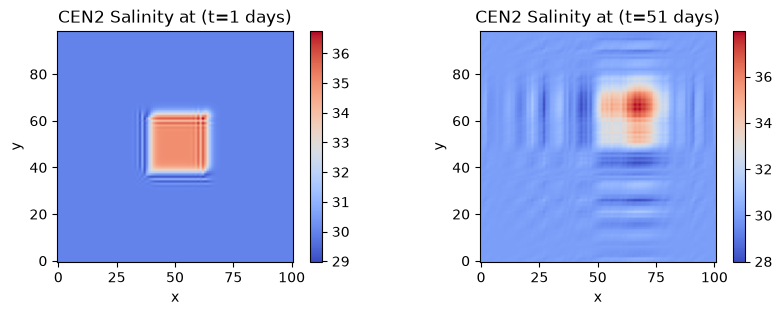

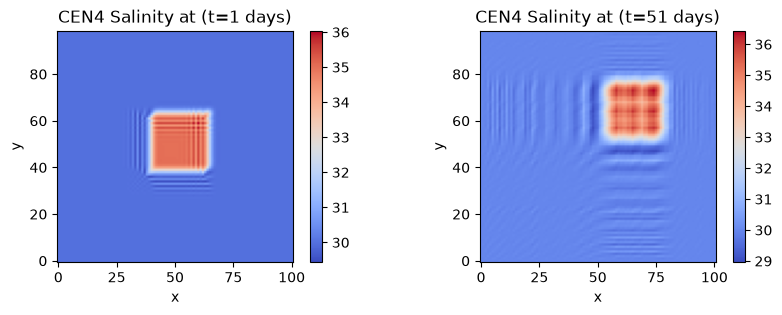

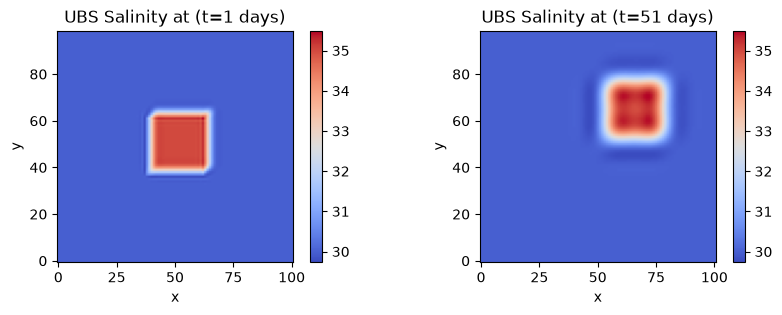

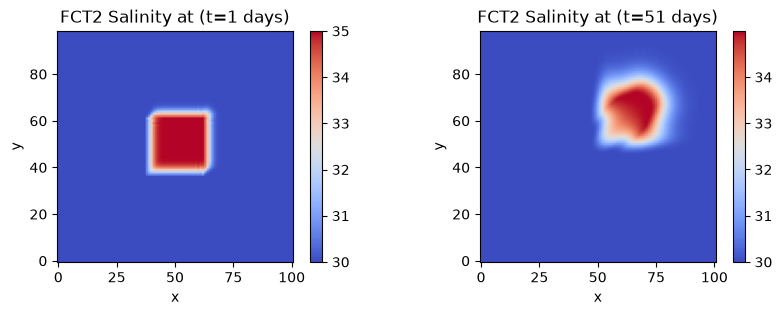

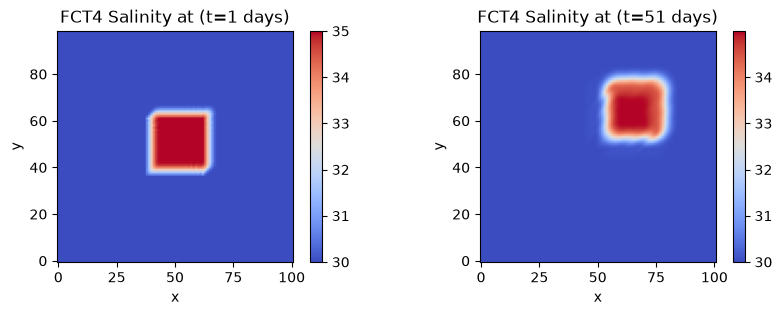

In [14]:
show_t([0, 50], 'soce', 'CEN2 Salinity', 'CANAL_saltblock_diag_cen2_all_grid.nc')
show_t([0, 50], 'soce', 'CEN4 Salinity', 'CANAL_saltblock_diag_cen4_all_grid.nc')
show_t([0, 50], 'soce', 'UBS Salinity', 'CANAL_saltblock_diag_ubs_all_grid.nc')
show_t([0, 50], 'soce', 'FCT2 Salinity', 'CANAL_saltblock_diag_fct2_all_grid.nc')
show_t([0, 50], 'soce', 'FCT4 Salinity', 'CANAL_saltblock_diag_fct4_all_grid.nc')

## Comparative plots

### Salinity along the x-axis

In [19]:
schemes = {'cen2': cen2, 'cen4': cen4, 'fct2' : fct2, 'fct4' : fct4,  'ubs': ubs}
colors = {'cen2': 'red', 'cen4': 'orange',  'fct2' : 'green', 'fct4' : 'lightgreen', 'ubs': 'blue'}

soce = {n: ds['soce'].isel(y_grid_T=50, deptht=0).values
          for n, ds in schemes.items()}

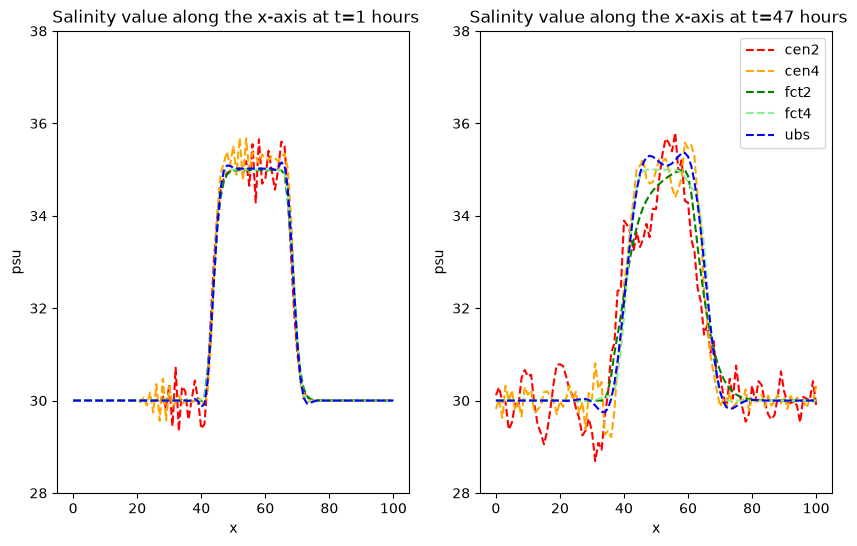

In [17]:
t_list = [1, 47]

fig, ax = plt.subplots(1, len(t_list), figsize=(10,6))

for i,t in enumerate(t_list):
    for n, ds in soce.items() :
        ax[i].plot(np.arange(ds.shape[1]), ds[t], '--', color = colors[n], label = n)
    ax[i].set_xlabel('x')
    ax[i].set_ylabel('psu')
    ax[i].set_ylim(28,38)
    ax[i].set_title(f' Salinity value along the x-axis at t={t} hours')

plt.legend()

### Salinity variance

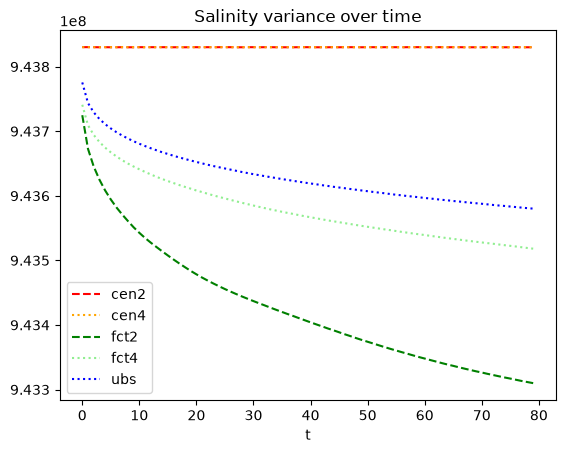

In [18]:
for n, ds in schemes.items() :
    if '4' in n:
        marker = ':'
    elif '2' in n :
        marker = '--'
    s2c = ds.salt2c.mean(dim=('x_grid_T', 'y_grid_T'))
    dep = np.arange(s2c.shape[0])
    plt.plot(dep,  s2c, marker, color =colors[n], label = n)
    

plt.title("Salinity variance over time")
plt.xlabel('t')

plt.legend()
plt.show()

In [8]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$
DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

#If the executive has another name than CANAL please inform it below
EXE=None

cd /"$DIR"

chmod -R a+x /"$DIR"/annex1_cfg/

bash /"$DIR"/annex1_cfg/end_diag.sh "$DIR"



+ set -u
+ '[' 1 -lt 1 ']'
+ DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
+ SRC=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg
+ '[' '!' -f /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg ']'
+ sed -i.bak -e 's/rn_domszx.*=.*\!/rn_domszx        =       1000.    !/' -e 's/rn_domszy.*=.*\!/rn_domszy        =       2000.   !/' -e 's/rn_domszz.*=.*\!/rn_domszz        =       1000.  !/' -e 's/rn_dx.*=.*\!/rn_dx        =       10.     !/' -e 's/rn_dy.*=.*\!/rn_dy        =       10.  !/' -e 's/rn_dz.*=.*\!/rn_dz        =       1000.  !/' -e 's/rn_0xratio.*=.*\!/rn_0xratio      =       0.5  !/' -e 's/rn_0yratio.*=.*\!/rn_0yratio      =       0.5  !/' -e 's/nn_fcase.*=.*\!/nn_fcase  =       0  !/' -e 's/rn_ppgphi0.*=.*\!/rn_ppgphi0      =       38.5  !/' -e 's/rn_u10.*=.*\!/rn_u10      =       0.  !/' -e 's/rn_uzonal.*=.*\!/rn_uzonal        =       0.5  !/' -e 's/rn_ujetszx.*=.*\!/rn_ujetszx           

300c300
<                pssh(:,:) = - zf0 * rn_uzonal *gphit(:,:)* 1e3_wp /grav           
---
>                pssh(:,:) = - zf0 * rn_uzonal *gphit(:,:)* 1e3_wp /grav            
Changes applied. Saving : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.bak
Compilation lanc??e depuis : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo
Name of the executive : EXP42


+ cp /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90 /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.bak
+ mv /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.tmp /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90
+ echo 'Changes applied. Saving : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.bak'
+ DIR_NEMO=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo
+ cd /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo
++ pwd
+ echo 'Compilation lanc??e depuis : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo'
+ FILE=EXP42/EXP00
+ TEST=EXP42
+ echo 'Name of the executive : EXP42'
+ ./makenemo -r CANAL -n CANAL


-e 



You are compiling an existing configuration CANAL with sub-components: OCE


Creating /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/CANAL/WORK = /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/src/OCE for CANAL

/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/CANAL/MY_SRC content is linked to /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/CANAL/WORK

--------------------------------------------------------------------------------
Compilation
--------------------------------------------------------------------------------



Use of uninitialized value in numeric gt (>) at /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/ext/FCM/bin/../lib/Fcm/BuildTask.pm line 176.


Build command started on Fri Oct 23 10:38:04 2026.
->Parse configuration: start
Config file (bld): /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/CANAL/BLD/bld.cfg
Config file (bld): /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/CANAL/BLD/arch_nemo.fcm
Config file (bld): /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/CANAL/BLD/cpp.fcm
->Parse configuration: 0 second
->Setup destination: start
Destination: jbuisson@resos-MBP.lan:/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/CANAL/BLD
->Setup destination: 0 second
->Setup build: start
->Setup build: 0 second
->Pre-process: start
No. of files scanned for PP dependency: 2
->Pre-process: 1 second
->Scan dependency: start
->Scan dependency: 0 second
->Generate Fortran interface: start
->Generate Fortran interface: 0 second
->Make: start
->Make: 0 second
->TOTAL: 1 second
Build command finished on Fri Oct 23 10:38:05 2026.

--------------------------------------------------------------------------------
C

+ cd /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
++ pwd
+ echo 'De retour dans : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00'


De retour dans : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
